# Analyse du taux de désabonnement des clients

## Projet de Data Analysis — Telco Customer Churn

## 1. Présentation du projet

### Contexte

Une entreprise de télécommunications propose différents services à ses clients. Certains clients quittent l'entreprise, tandis que d'autres restent abonnés.

Le départ d'un client peut réduire les revenus de l'entreprise. Il est donc utile de comprendre quels profils présentent les taux de désabonnement les plus élevés.

### Problématique

> **Quels facteurs sont associés au désabonnement des clients, et quels segments semblent nécessiter une attention particulière ?**

### Objectifs

- calculer le taux global de désabonnement ;
- comprendre la structure du dataset ;
- nettoyer les données sans supprimer artificiellement des clients ;
- comparer le churn selon le contrat, l'ancienneté, les services et le paiement ;
- produire quelques graphiques utiles ;
- proposer des recommandations simples et prudentes.

### Questions de l'analyse

1. Quel est le taux global de désabonnement ?
2. Le type de contrat est-il associé au churn ?
3. Les clients récents quittent-ils davantage l'entreprise ?
4. Les clients ayant des frais mensuels élevés se désabonnent-ils davantage ?
5. Le service Internet ou le mode de paiement sont-ils associés à des taux différents ?
6. Quels profils peuvent être considérés comme prioritaires pour une action de fidélisation ?

## 2. Importation des bibliothèques

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 3. Chargement des données

In [3]:
# Chemin vers le fichier CSV
chemin_fichier = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

# Chargement des données
df = pd.read_csv(chemin_fichier)

## 4. Première exploration des données

In [4]:
# Affichage des premières lignes
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# Nombre de lignes et de colonnes
df.shape

(7043, 21)

Le dataset contient **7 043 lignes** et **21 colonnes**
- Chaque ligne représente un client.
- Chaque colonne contient une information sur ce client, par exemple son contrat, son ancienneté ou ses frais mensuels.

In [6]:
# Informations sur les colonnes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

La majorité des colonnes sont catégorielles. **tenure** et **MonthlyCharges** sont numériques.

 la colonne **TotalCharges** est enregistré comme du texte alors qu'il représente un montant. Nous la transformerons dans la partie nettoyage.

In [7]:
# Nombre de valeurs manquantes
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Pas de valeurs manquantes détecté.

In [8]:
# Vérification des doublons et des identifiants
print("Nombre de doublons :", df.duplicated().sum())

# Vérification des identifiants clients
print("Nombre de lignes :", len(df))
print("Identifiants uniques :", df["customerID"].nunique())

Nombre de doublons : 0
Nombre de lignes : 7043
Identifiants uniques : 7043


In [9]:
# Nombre de valeurs différentes dans chaque colonne
df.nunique()

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

## 5. Nettoyage des données

In [10]:
# Conversion de la colonne TotalCharges en nombres
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [11]:
# Verification du nombre de valeurs manquantes
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [12]:
# clients dont le TotalCharges est manquant
client_manquant = df["TotalCharges"].isnull()

# Colonnes utiles pour comprendre ces cas
colonnes_a_voir = ["customerID", "tenure", "MonthlyCharges",
                   "TotalCharges", "Churn"]

# Affichage des lignes concernées
df.loc[client_manquant, colonnes_a_voir]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


Nous trouvons **11 cellules vides** dans **TotalCharges**. Ces lignes correspondent toutes à des clients dont l'ancienneté est de **0 mois**.

Cela signifie probablement que ces clients viennent de commencer leur abonnement et qu'aucun montant total n'a encore été enregistré. Nous allons donc remplacer ces valeurs par **0**, plutôt que de supprimer ces clients.

In [13]:
# Imputation de la colonne TotalCharges par 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Verification
print("Valeurs manquantes restantes :", df["TotalCharges"].isnull().sum())

Valeurs manquantes restantes : 0


## 6. Analyse descriptive globale

In [14]:
# Statistiques descriptives des variables numériques
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


**tenure** représente l'ancienneté du client en mois.

- L'ancienneté moyenne est d'environ **32 mois**.
- La moitié des clients ont une ancienneté inférieure ou égale à **29 mois**.
- Les valeurs vont de **0 à 72 mois**.

**MonthlyCharges** représente les frais payés chaque mois.

- La moyenne est d'environ **64,76**.
- La moitié des clients paient au plus environ **70,35** par mois.
- Les valeurs vont de **18,25 à 118,75**.

In [15]:
# Comptage des clients selon leur statut
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [16]:
# Calcul du taux global de désabonnement
taux_churn = (df["Churn"] == "Yes").mean() * 100
print("Taux global de désabonnement :", round(taux_churn, 2), "%")

Taux global de désabonnement : 26.54 %


1 869 clients ont quitté l'entreprise, tandis que 5 174 clients sont restés.

Le taux global de désabonnement est donc de **26,54 %**. Il ya donc environ **1 client sur 4** qui se désabonnement.

## 7. Analyse exploratoire univariée et bivariée


### Distribution de l'ancienneté

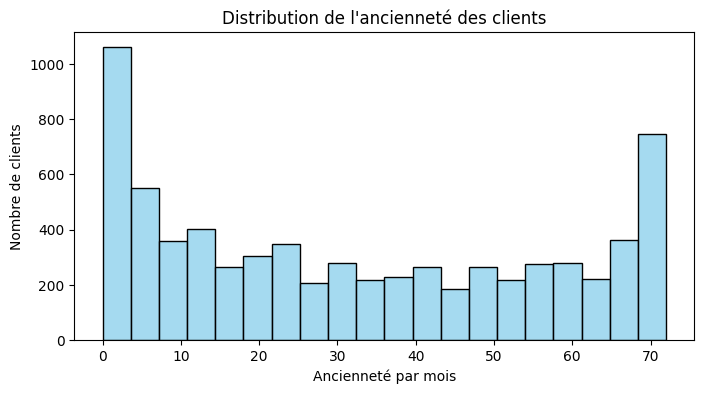

In [17]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="tenure", bins=20, color="skyblue")
plt.title("Distribution de l'ancienneté des clients")
plt.xlabel("Ancienneté par mois")
plt.ylabel("Nombre de clients")
plt.show()

Les clients ne sont pas répartis de manière régulière selon leur ancienneté. On observe beaucoup de clients très récents et également beaucoup de clients présents depuis longtemps, Entre les deux extremes environs le meme nombre de client.

### Répartition des clients selon le churn

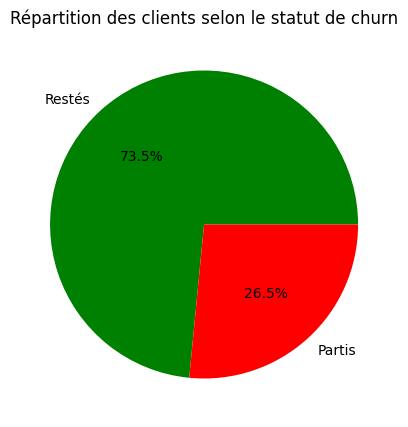

In [18]:
# Nombre de clients par statut
effectifs = df["Churn"].value_counts()

plt.figure(figsize=(5, 5))
plt.pie(effectifs, labels=["Restés", "Partis"], autopct="%1.1f%%", colors=["green", "red"])
plt.title("Répartition des clients selon le statut de churn")
plt.savefig("figures/repartition_churn.png")
plt.show()

73,46 % des clients sont restés et 26,54 % se sont désabonnés. Les clients restés sont donc majoritaires.

Cependant, le churn concerne environ **1 client sur 4**, ce qui représente une part suffisamment importante pour que l'entreprise cherche à comprendre les profils les plus exposés.

### Analyse du type de contrat
**le taux de churn est-il différent selon le type de contrat ?**

In [ ]:
# taux de churn par type de contrat
churn_par_contrat = df.groupby("Contract")["Churn"].apply(lambda colonne: (colonne == "Yes").mean() * 100).sort_values(ascending=False)

churn_par_contrat.round(2)

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

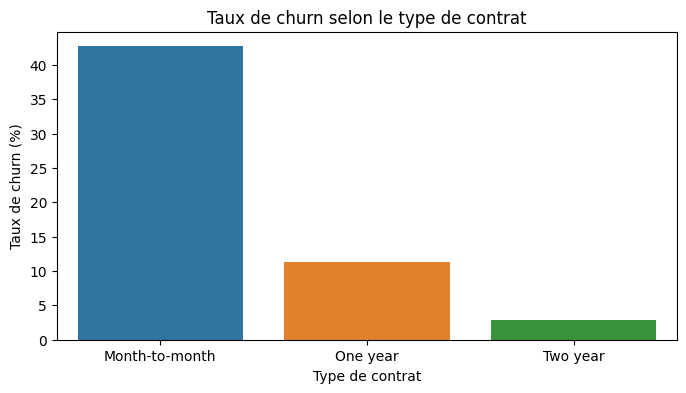

In [37]:
plt.figure(figsize=(8, 4))
sns.barplot(x=churn_par_contrat.index, y=churn_par_contrat.values, hue=churn_par_contrat.index)
plt.title("Taux de churn selon le type de contrat")
plt.xlabel("Type de contrat")
plt.ylabel("Taux de churn (%)")
plt.savefig("figures/taux_churn_contrat.png")
plt.show()

Le taux de churn est de **42,71 %** pour les contrats mensuels, contre **11,27 %** pour les contrats d'un an et **2,83 %** pour les contrats de deux ans.

les clients en contrat mensuel partent donc beaucoup plus souvent que les clients ayant un contrat plus long. Le contrat mensuel est **associé** à un churn plus élevé.

On peut supposer que le contrat peut etre la cause du départ. Mais il est possible que les clients qui choisissent un contrat mensuel aient déjà un profil différent ou soient moins engagés dans la durée.

### Analyse de l'ancienneté
**les clients récents quittent-ils davantage l'entreprise ?**

In [21]:
# Regroupement de l'ancienneté en tranches
df["TenureGroup"] = pd.cut(df["tenure"], bins=[0, 12, 24, 48, 72], labels=["0-12 mois", "13-24 mois", "25-48 mois", "49-72 mois"],
)

churn_par_anciennete = df.groupby("TenureGroup", observed=False)["Churn"].apply(lambda colonne: (colonne == "Yes").mean() * 100)
churn_par_anciennete.round(2)

TenureGroup
0-12 mois     47.68
13-24 mois    28.71
25-48 mois    20.39
49-72 mois     9.51
Name: Churn, dtype: float64

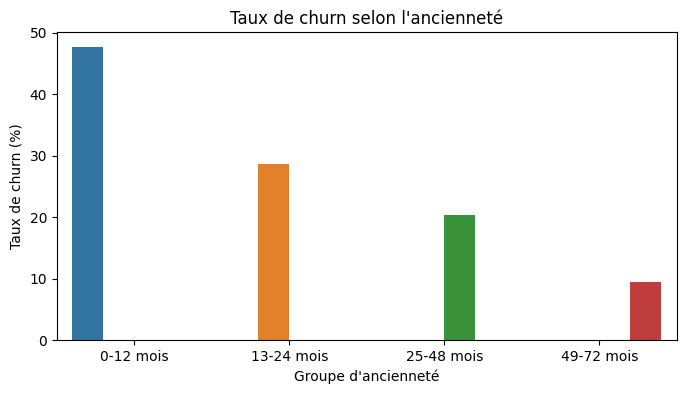

In [38]:
plt.figure(figsize=(8, 4))
sns.barplot(x=churn_par_anciennete.index, y=churn_par_anciennete.values, hue=churn_par_anciennete.index)
plt.title("Taux de churn selon l'ancienneté")
plt.xlabel("Groupe d'ancienneté")
plt.ylabel("Taux de churn (%)")
plt.savefig("figures/taux_churn_anciennete.png")
plt.show()

Le taux de churn est d'environ **47,44 %** chez les clients ayant entre 0 et 12 mois d'ancienneté. Il baisse ensuite à **28,71 %**, **20,39 %**, puis **9,51 %** chez les clients les plus anciens.

Les clients récents quittent donc plus souvent l'entreprise. Les douze premiers mois semblent être une période importante pour la fidélisation. C'est donc un groupe à surveiller.

#### Comparaison des moyennes d'ancienneté

In [23]:
df.groupby("Churn")["tenure"].agg(["count", "mean", "median"]).round(2)

,count,mean,median
Churn,,,
No,5174,37.57,38.0
Yes,1869,17.98,10.0


Les clients désabonnés ont une ancienneté moyenne d'environ **18 mois**, contre environ **38 mois** pour les clients restés.

La médiane confirme cette différence : la moitié des clients désabonnés ont une ancienneté inférieure ou égale à **10 mois**, contre **38 mois** pour les clients restés.

### Analyse des frais mensuels
**les clients désabonnés ont-ils des frais mensuels plus élevés ?**

In [24]:
df.groupby("Churn")["MonthlyCharges"].agg(["count", "mean", "median"]).round(2)

,count,mean,median
Churn,,,
No,5174,61.27,64.43
Yes,1869,74.44,79.65


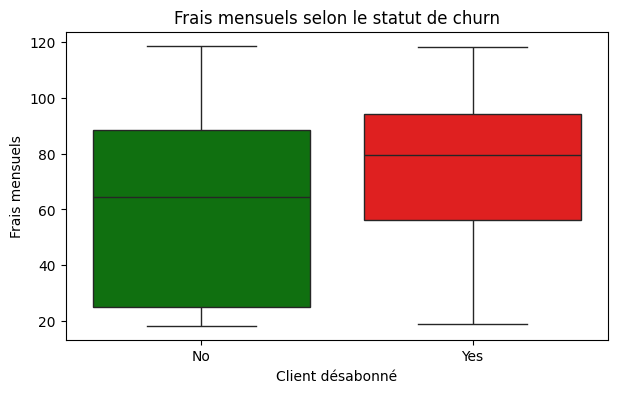

In [39]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", hue="Churn", palette=["green", "red"])
plt.title("Frais mensuels selon le statut de churn")
plt.xlabel("Client désabonné")
plt.ylabel("Frais mensuels")
plt.savefig("figures/frais_mensuels_churn.png")
plt.show()

Les clients désabonnés paient en moyenne **74,44** par mois, contre **61,27** pour les clients restés. La médiane est également plus élevée chez les clients désabonnés : **79,65** contre **64,43**.

les clients qui partent ont donc souvent des frais mensuels plus élevés.

On peut donc supposer que le prix est peut etre la cause du départ. Mais des frais élevés peuvent correspondre à davantage de services, à un autre type de contrat ou à un profil de client différent.

### Analyse du service Internet
**le service Internet est-il associé à des taux de churn différents ?**

In [ ]:
churn_par_internet = df.groupby("InternetService")["Churn"].apply(lambda colonne: (colonne == "Yes").mean() * 100).sort_values(ascending=False)

churn_par_internet.round(2)

InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64

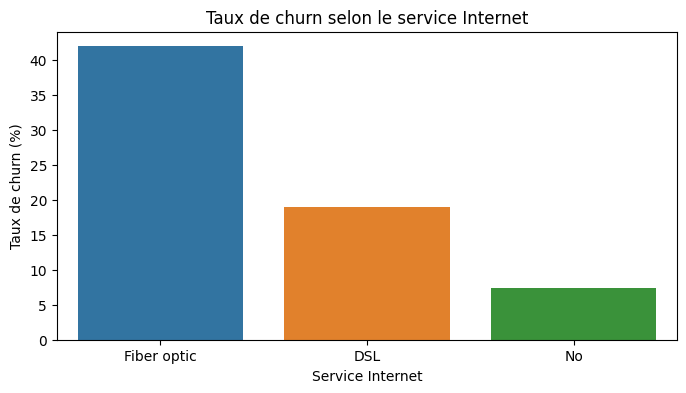

In [40]:
plt.figure(figsize=(8, 4))
sns.barplot(x=churn_par_internet.index, y=churn_par_internet.values, hue=churn_par_internet.index)
plt.title("Taux de churn selon le service Internet")
plt.xlabel("Service Internet")
plt.ylabel("Taux de churn (%)")
plt.savefig("figures/taux_churn_internet.png")
plt.show()

Le taux de churn est de **41,89 %** chez les clients utilisant la fibre optique, contre **18,96 %** pour le DSL et **7,40 %** pour les clients sans service Internet.

La fibre optique représente donc un groupe à examiner en priorité. Ce résultat ne signifie pas que la fibre provoque nécessairement les départs. Il faudrait aussi vérifier les frais mensuels, le type de contrat, la qualité du service et les éventuelles réclamations.

### Analyse du mode de paiement
**certains modes de paiement sont-ils associés à un taux de churn plus élevé ?**

In [28]:
churn_par_paiement = df.groupby("PaymentMethod")["Churn"].apply(lambda colonne: (colonne == "Yes").mean() * 100).sort_values(ascending=False)
churn_par_paiement.round(2)

PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64

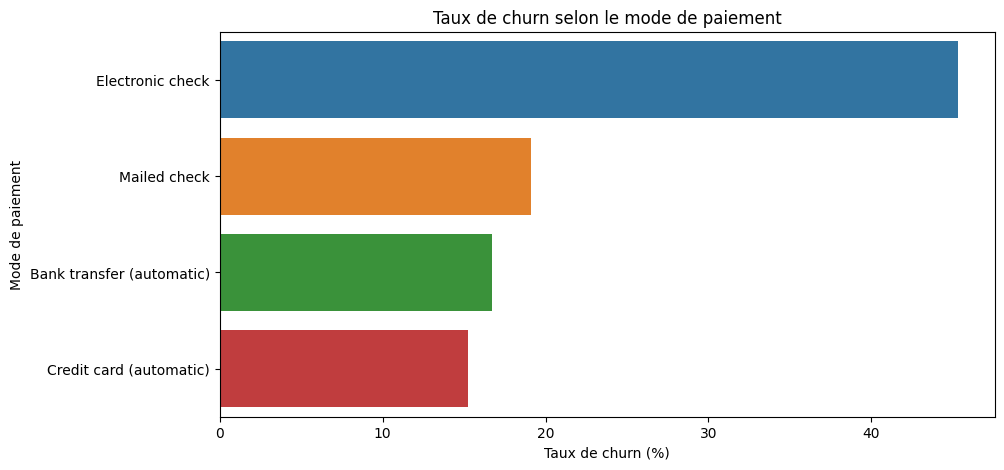

In [41]:
plt.figure(figsize=(10, 5))
sns.barplot(x=churn_par_paiement.values, y=churn_par_paiement.index, hue=churn_par_paiement.index)
plt.title("Taux de churn selon le mode de paiement")
plt.xlabel("Taux de churn (%)")
plt.ylabel("Mode de paiement")
plt.savefig("figures/taux_churn_paiement.png")
plt.show()

Le taux de churn est le plus élevé chez les clients utilisant **Electronic check**, avec **45,29 %**. Il est plus faible chez les clients utilisant un virement automatique ou une carte bancaire automatique, avec environ **15 à 17 %**.

Le mode de paiement est peut etre associé au churn. On peut donc orienter les clients sur les moyens de paiement.

### Comparaison des profils : clients restés et désabonnés


In [30]:
# Comparaison des caractéristiques selon le churn
resume_churn = df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].agg(["mean", "median"]).round(2)
resume_churn

tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43      2549.91  1679.52
Yes    17.98   10.0          74.44  79.65      1531.80   703.55

Les clients désabonnés ont une ancienneté plus faible et des frais mensuels plus élevés en moyenne.

Leur montant total payé est plus faible. Cela peut s'expliquer par le fait que : comme ils restent moins longtemps, ils ont moins de temps pour accumuler des paiements.

### Relation entre ancienneté et frais mensuels

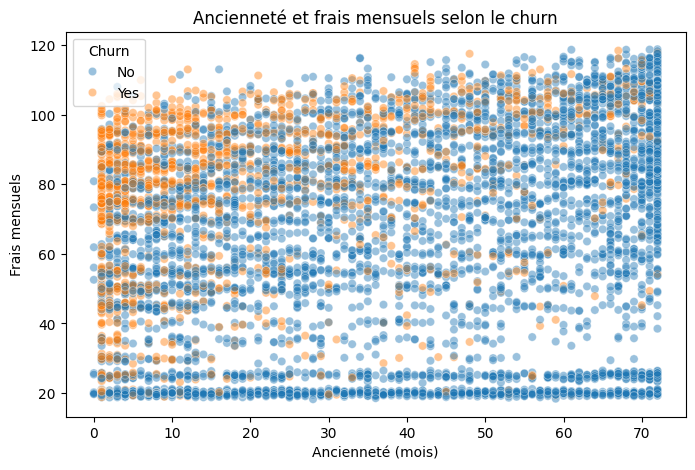

In [42]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="tenure", y="MonthlyCharges", hue="Churn", alpha=0.45,)
plt.title("Ancienneté et frais mensuels selon le churn")
plt.xlabel("Ancienneté (mois)")
plt.ylabel("Frais mensuels")
plt.savefig("figures/anciennete_frais_churn.png")
plt.show()

Les clients désabonnés sont nombreux dans la zone des faibles anciennetés. Les frais mensuels sont aussi souvent plus élevés chez eux, mais les points sont dispersés.

On peut donc supposer que la faible ancienneté et les frais mensuels élevés sont **associés** au churn et que les frais élevés sont peut etre la cause du départ.

## 8. Analyse multivariée simple

In [32]:
# Taux de churn selon le contrat et le groupe d'ancienneté
churn_contrat_anciennete = pd.pivot_table(df, values="Churn", index="TenureGroup", columns="Contract", aggfunc=lambda colonne: (colonne == "Yes").mean() * 100)
churn_contrat_anciennete.round(2)

Contract,Month-to-month,One year,Two year
TenureGroup,,,
0-12 mois,51.35,10.57,0.00
13-24 mois,37.72,8.12,0.00
25-48 mois,32.92,10.62,2.19
49-72 mois,26.02,12.93,3.33


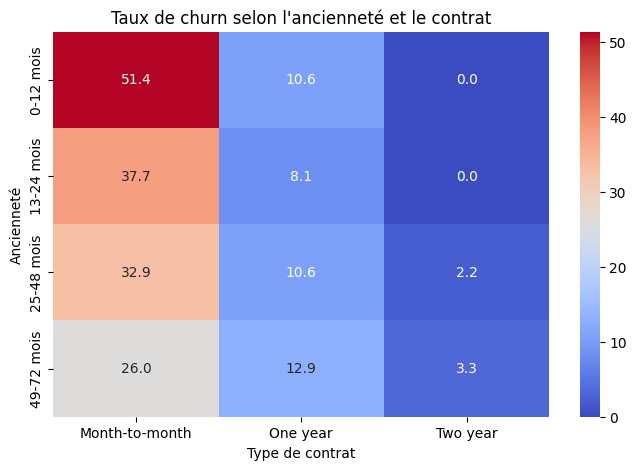

In [43]:
plt.figure(figsize=(8, 5))
sns.heatmap(churn_contrat_anciennete, annot=True, fmt=".1f", cmap="coolwarm")
plt.title("Taux de churn selon l'ancienneté et le contrat")
plt.xlabel("Type de contrat")
plt.ylabel("Ancienneté")
plt.savefig("figures/taux_churn_contrat_anciennete.png")
plt.show()


Le groupe le plus exposé est celui des clients en contrat mensuel et présents depuis 0 à 12 mois : son taux de churn est d'environ **51,35 %**. Cela signifie qu'un peu plus d'un client sur deux de ce groupe est parti dans le dataset.

## 9. Corrélations entre variables numériques

In [34]:
variables_numeriques = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
correlations = df[variables_numeriques].corr()
correlations.round(2)

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.00,0.02,0.22,0.10
tenure,0.02,1.00,0.25,0.83
MonthlyCharges,0.22,0.25,1.00,0.65
TotalCharges,0.10,0.83,0.65,1.00


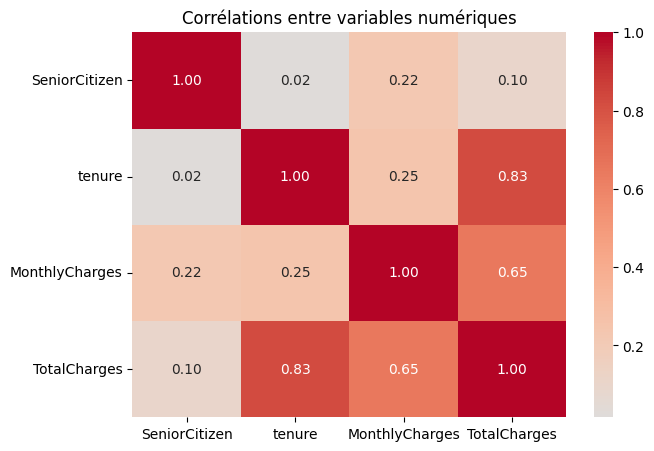

In [44]:
plt.figure(figsize=(7, 5))
sns.heatmap(correlations, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Corrélations entre variables numériques")
plt.savefig("figures/correlations_numeriques.png")
plt.show()

La corrélation la plus forte est observée entre **tenure** et **TotalCharges**, avec une valeur de **0,83**. Cela signifie que les clients présents depuis longtemps ont généralement payé un montant total plus élevé. Cela peut s'expliquer par le fait qu'ils ont eu davantage de mois pour accumuler des paiements.

La corrélation entre **tenure** et **MonthlyCharges** est plus faible, avec une valeur de **0,25**. Cela indique une relation limitée entre l'ancienneté et le montant payé chaque mois.


In [36]:
# Tableau récapitulatif de quelques taux importants
synthese = pd.DataFrame({
    "Indicateur": [
        "Taux global",
        "Contrat mensuel",
        "Ancienneté 0-12 mois",
        "Fibre optique",
        "Electronic check"
    ],
    "Taux de churn (%)": [
        taux_churn,
        churn_par_contrat["Month-to-month"],
        churn_par_anciennete["0-12 mois"],
        churn_par_internet["Fiber optic"],
        churn_par_paiement["Electronic check"]
    ]
})
synthese.round(2)

,Indicateur,Taux de churn (%)
0,Taux global,26.54
1,Contrat mensuel,42.71
2,Ancienneté 0-12 mois,47.68
3,Fibre optique,41.89
4,Electronic check,45.29


Les résultats les plus importants sont les suivants :

- le taux global de churn est de **26,54 %** ;
- les clients en contrat mensuel ont un taux de churn de **42,71 %** ;
- les clients ayant entre 0 et 12 mois d'ancienneté ont un taux d'environ **47,44 %** ;
- les clients utilisant la fibre optique ont un taux de **41,89 %** ;
- les clients utilisant **Electronic check** ont un taux de **45,29 %** ;
- le groupe qui combine un contrat mensuel et une ancienneté de 0 à 12 mois atteint environ **51,35 %**.


## 16. Recommandations simples

### 1. Accompagner les clients pendant leurs 12 premiers mois

Le taux de churn est particulièrement élevé chez les clients récents. L'entreprise pourrait envoyer un message de bienvenue, proposer une aide à l'installation et vérifier la satisfaction après quelques mois.

### 2. Porter une attention particulière aux clients en contrat mensuel

Le taux de churn est de 42,71 % dans ce groupe. L'entreprise pourrait présenter clairement les avantages d'un contrat plus long ou proposer une offre de fidélisation. Cette proposition doit rester volontaire et transparente.

### 3. Vérifier l'expérience des clients utilisant la fibre optique

Le taux de churn de ce groupe est élevé. Avant de modifier l'offre, il faudrait vérifier les réclamations, les interruptions de service, les frais et le niveau de satisfaction.

### 4. Mieux comprendre les clients utilisant **Electronic check**

Ce groupe présente un taux de churn élevé. L'entreprise pourrait vérifier s'il existe des problèmes de paiement, puis expliquer les autres modes de paiement disponibles.

Ces recommandations devront ensuite être testées avec de nouvelles données pour vérifier si elles réduisent réellement le churn.